# 🌸 Flower Classification with Deep Learning

### Computer Vision | 14-Class Image Classification | CNN Transfer Learning

This project classifies flower photographs into **14 flower categories** using a pre-trained **MobileNetV2** model

**Project goal:** Build an image classifier that recognizes flower types and evaluates its predictions on unseen images

**Dataset:** 13,642 training records and 98 validation records across 14 classes. The CSV files contain image paths and labels; the corresponding JPG images are required

**Method:** Multiclass Classification with CNN-based Transfer Learning

> To keep training lightweight, the first experiment uses up to 2,800 training images, 160 × 160 pixel images, and a maximum of 5 epochs

## 📖 Data Dictionary

| Field / File | Description |
|---|---|
| `image:FILE` | Relative path to a flower JPG image |
| `category` | Flower class ID (0–13) — **target (y)** |
| `classname.txt` | Original class names in label order |
| `train/` | Training photographs |
| `val/` | Validation photographs |

**Flower classes:** Carnation, Iris, Bellflower, Golden trumpet, Rose, Astilbe, Tulip, Marigold, Dandelion, Coreopsis, Black-eyed Susan, Water lily, Sunflower and Daisy.

The English class names are used for display; the numeric labels determine the model targets.

## 1. Import Libraries

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


## 2. Load Dataset & Data Overview

In [2]:
# CSV and folder paths are relative to the notebook's working folder.
TRAIN_CSV = Path("train.csv")
VAL_CSV = Path("val.csv")
CLASS_FILE = Path("classname.txt")

for file in (TRAIN_CSV, VAL_CSV, CLASS_FILE):
    if not file.is_file():
        raise FileNotFoundError(f"Missing {file}. Place it next to the notebook and restart.")

train_df = pd.read_csv(TRAIN_CSV).rename(columns={"image:FILE": "image_path"})
val_df = pd.read_csv(VAL_CSV).rename(columns={"image:FILE": "image_path"})
original_class_names = [line.strip() for line in CLASS_FILE.read_text(encoding="utf-8-sig").splitlines() if line.strip()]

# English display names in the same order as classname.txt
flower_names = [
    "Carnation", "Iris", "Bellflower", "Golden trumpet", "Rose", "Astilbe",
    "Tulip", "Marigold", "Dandelion", "Coreopsis", "Black-eyed Susan",
    "Water lily", "Sunflower", "Daisy"
]
NUM_CLASSES = len(original_class_names)
assert NUM_CLASSES == len(flower_names) == 14
assert set(train_df.columns) == set(val_df.columns) == {"image_path", "category"}
assert train_df["category"].between(0, NUM_CLASSES - 1).all()
assert val_df["category"].between(0, NUM_CLASSES - 1).all()

print("Train:", train_df.shape, "| Validation:", val_df.shape, "| Classes:", NUM_CLASSES)
print("Missing values:")
display(train_df.isna().sum().to_frame("Train"))
print("Duplicate rows (train):", train_df.duplicated().sum())
display(train_df.head())

Train: (13642, 2) | Validation: (98, 2) | Classes: 14
Missing values:


,Train
image_path,0
category,0


Duplicate rows (train): 0


,image_path,category
0,train/carnation/6838762136_f8254d6a1a_c.jpg,0
1,train/carnation/3540544866_823aee81af_c.jpg,0
2,train/carnation/50034862576_b0f55b7b3b_c.jpg,0
3,train/carnation/26770795691_f662e47143_c.jpg,0
4,train/carnation/18224456534_2f75191d85_c.jpg,0


## 3. Exploratory Data Analysis

We examine **class distribution** and example flower images. Numeric correlations and outlier analysis are less useful for this image classification task

,Flower,Training images,Validation images
0,Carnation,924,7
1,Iris,1041,7
2,Bellflower,872,7
3,Golden trumpet,1021,7
4,Rose,986,7
5,Astilbe,726,7
6,Tulip,1034,7
7,Marigold,1011,7
8,Dandelion,1038,7
9,Coreopsis,1035,7


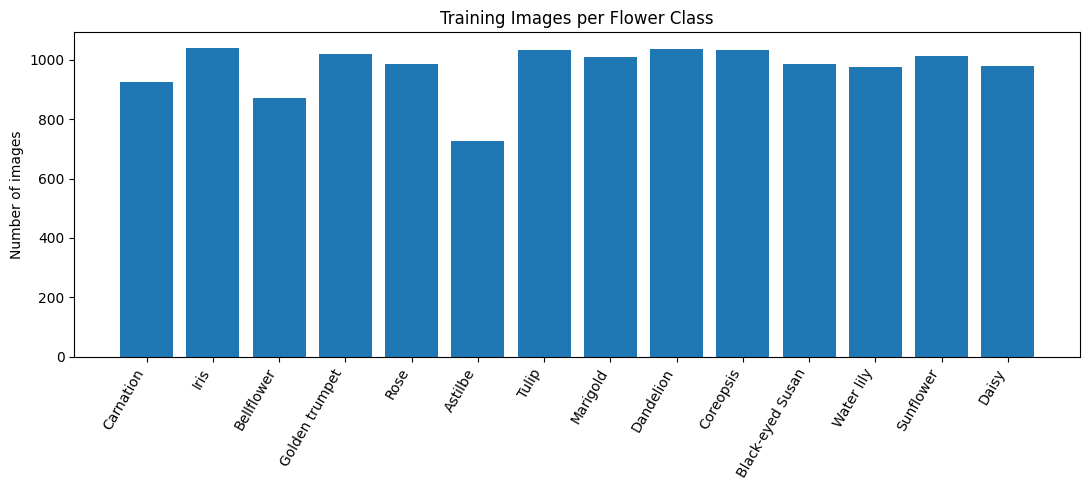

In [3]:
class_counts = train_df["category"].value_counts().sort_index()
summary = pd.DataFrame({
    "Flower": flower_names,
    "Training images": class_counts.reindex(range(14), fill_value=0).values,
    "Validation images": val_df["category"].value_counts().reindex(range(14), fill_value=0).values
})
display(summary)

plt.figure(figsize=(11, 5))
plt.bar(summary["Flower"], summary["Training images"])
plt.title("Training Images per Flower Class")
plt.ylabel("Number of images")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

## 4. Flower Image Visualization

Check the JPG paths and display one example per class before training

In [4]:
DATA_ROOT = Path(".")  # Change to Path("dataset") only if train/ and val/ are inside dataset/

train_df["full_path"] = train_df["image_path"].map(lambda p: str(DATA_ROOT / p))
val_df["full_path"] = val_df["image_path"].map(lambda p: str(DATA_ROOT / p))

missing_train = sum(not Path(p).is_file() for p in train_df["full_path"])
missing_val = sum(not Path(p).is_file() for p in val_df["full_path"])
IMAGES_READY = missing_train == 0 and missing_val == 0

print(f"Missing training JPGs: {missing_train:,} / {len(train_df):,}")
print(f"Missing validation JPGs: {missing_val:,} / {len(val_df):,}")
print("Images ready:", IMAGES_READY)
if not IMAGES_READY:
    print("Example expected path:", train_df["full_path"].iloc[0])
    print("Check whether the JPG files are in train/ and val/ or adjust DATA_ROOT.")

Missing training JPGs: 0 / 13,642
Missing validation JPGs: 0 / 98
Images ready: True


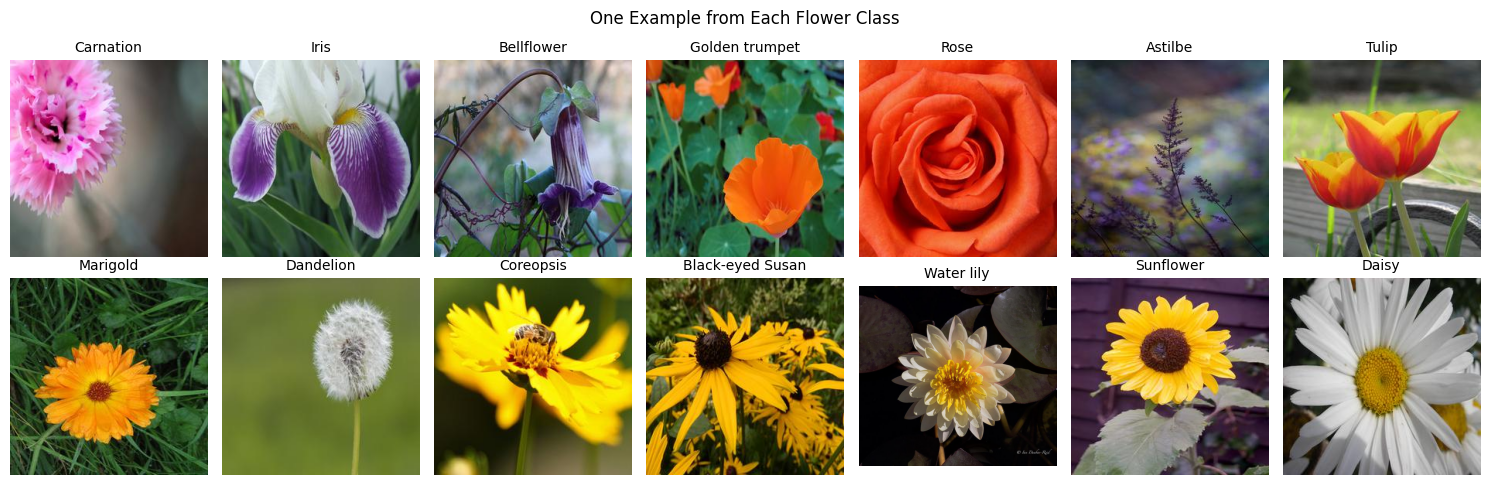

In [5]:
if IMAGES_READY:
    from PIL import Image
    examples = train_df.groupby("category", group_keys=False).sample(n=1, random_state=RANDOM_STATE)
    fig, axes = plt.subplots(2, 7, figsize=(15, 5))
    for ax, (_, row) in zip(axes.flat, examples.iterrows()):
        with Image.open(row["full_path"]) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(flower_names[int(row["category"])], fontsize=10)
        ax.axis("off")
    plt.suptitle("One Example from Each Flower Class")
    plt.tight_layout()
    plt.show()
else:
    print("Add the JPG files first to display sample flowers and run the CNN.")

## 5. Image Preprocessing & Data Split

Resize images to **160 × 160**, then create training, validation, and independent test sets. We use a limited training sample to reduce computation

In [6]:
if not IMAGES_READY:
    raise FileNotFoundError("Flower JPG files are missing. Fix DATA_ROOT and keep train/ and val/ images before continuing.")

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split

tf.random.set_seed(RANDOM_STATE)
IMAGE_SIZE = (160, 160)
BATCH_SIZE = 16  # Smaller batches to reduce laptop memory usage
MAX_TRAIN_IMAGES = 2800

# Independent, stratified holdout test set from training CSV.
train_pool, test_df = train_test_split(
    train_df, test_size=0.15, random_state=RANDOM_STATE, stratify=train_df["category"]
)
if MAX_TRAIN_IMAGES is not None and len(train_pool) > MAX_TRAIN_IMAGES:
    train_small, _ = train_test_split(
        train_pool, train_size=MAX_TRAIN_IMAGES,
        stratify=train_pool["category"], random_state=RANDOM_STATE
    )
else:
    train_small = train_pool.copy()

def make_dataset(frame, training=False):
    paths = frame["full_path"].astype(str).to_numpy()
    labels = frame["category"].astype("int32").to_numpy()
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(frame), seed=RANDOM_STATE, reshuffle_each_iteration=True)

    def load_image(path, label):
        image = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
        image = tf.image.resize(image, IMAGE_SIZE)
        return image, label

    return ds.map(load_image, num_parallel_calls=2).batch(BATCH_SIZE).prefetch(1)

train_ds = make_dataset(train_small, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)  # Order must match test_df for metrics
print("Training:", len(train_small), "| Validation:", len(val_df), "| Test:", len(test_df))
print("TensorFlow version:", tf.__version__)

Training: 2800 | Validation: 98 | Test: 2047
TensorFlow version: 2.18.0


## 6. CNN Model — Transfer Learning

MobileNetV2 extracts image features, while a small classification layer learns the **14 flower classes**. The pre-trained backbone stays frozen

In [7]:
augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
], name="augmentation")

base_model = keras.applications.MobileNetV2(
    input_shape=(*IMAGE_SIZE, 3), include_top=False, weights="imagenet"
)
base_model.trainable = False

inputs = keras.Input(shape=(*IMAGE_SIZE, 3))
x = augmentation(inputs)
x = layers.Rescaling(scale=1 / 127.5, offset=-1)(x)  # MobileNetV2 expects [-1, 1]
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.25)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
model = keras.Model(inputs, outputs)
model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 160, 160, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ augmentation (Sequential)            │ (None, 160, 160, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 160, 160, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_160 (Functional)    │ (None, 5, 5, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 14)                  │          17,934 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,275,918 (8.68 MB)

 Trainable params: 17,934 (70.05 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 7. Model Training

Train for up to **5 epochs**, using early stopping to avoid unnecessary training

In [8]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
]
history = model.fit(train_ds, validation_data=val_ds, epochs=5, callbacks=callbacks)

Epoch 1/5
175/175 ━━━━━━━━━━━━━━━━━━━━ 22s 92ms/step - accuracy: 0.3905 - loss: 1.9718 - val_accuracy: 0.8061 - val_loss: 0.6799
Epoch 2/5
175/175 ━━━━━━━━━━━━━━━━━━━━ 15s 83ms/step - accuracy: 0.8099 - loss: 0.6374 - val_accuracy: 0.8367 - val_loss: 0.5357
Epoch 3/5
175/175 ━━━━━━━━━━━━━━━━━━━━ 15s 83ms/step - accuracy: 0.8619 - loss: 0.4422 - val_accuracy: 0.8776 - val_loss: 0.4296
Epoch 4/5
175/175 ━━━━━━━━━━━━━━━━━━━━ 17s 97ms/step - accuracy: 0.8724 - loss: 0.4021 - val_accuracy: 0.8673 - val_loss: 0.4321
Epoch 5/5
175/175 ━━━━━━━━━━━━━━━━━━━━ 17s 95ms/step - accuracy: 0.8933 - loss: 0.3356 - val_accuracy: 0.8878 - val_loss: 0.4153


## 8. Model Evaluation

Review the training curve, **Accuracy**, **Precision**, **Recall**, **F1-score**, and **Confusion Matrix** on the independent test set

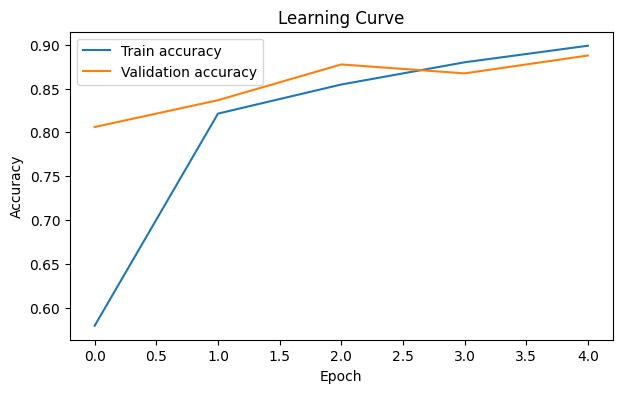

Test accuracy: 0.874
                  precision    recall  f1-score   support

       Carnation       0.94      0.76      0.84       139
            Iris       0.90      0.83      0.86       156
      Bellflower       0.71      0.72      0.71       131
  Golden trumpet       0.87      0.88      0.87       153
            Rose       0.89      0.91      0.90       148
         Astilbe       0.90      0.80      0.84       109
           Tulip       0.92      0.98      0.95       155
        Marigold       0.79      0.74      0.77       152
       Dandelion       0.98      0.92      0.95       156
       Coreopsis       0.84      0.88      0.86       155
Black-eyed Susan       0.96      0.93      0.94       148
      Water lily       0.77      0.99      0.87       146
       Sunflower       0.93      0.95      0.94       152
           Daisy       0.88      0.91      0.89       147

        accuracy                           0.87      2047
       macro avg       0.88      0.87      0.87  

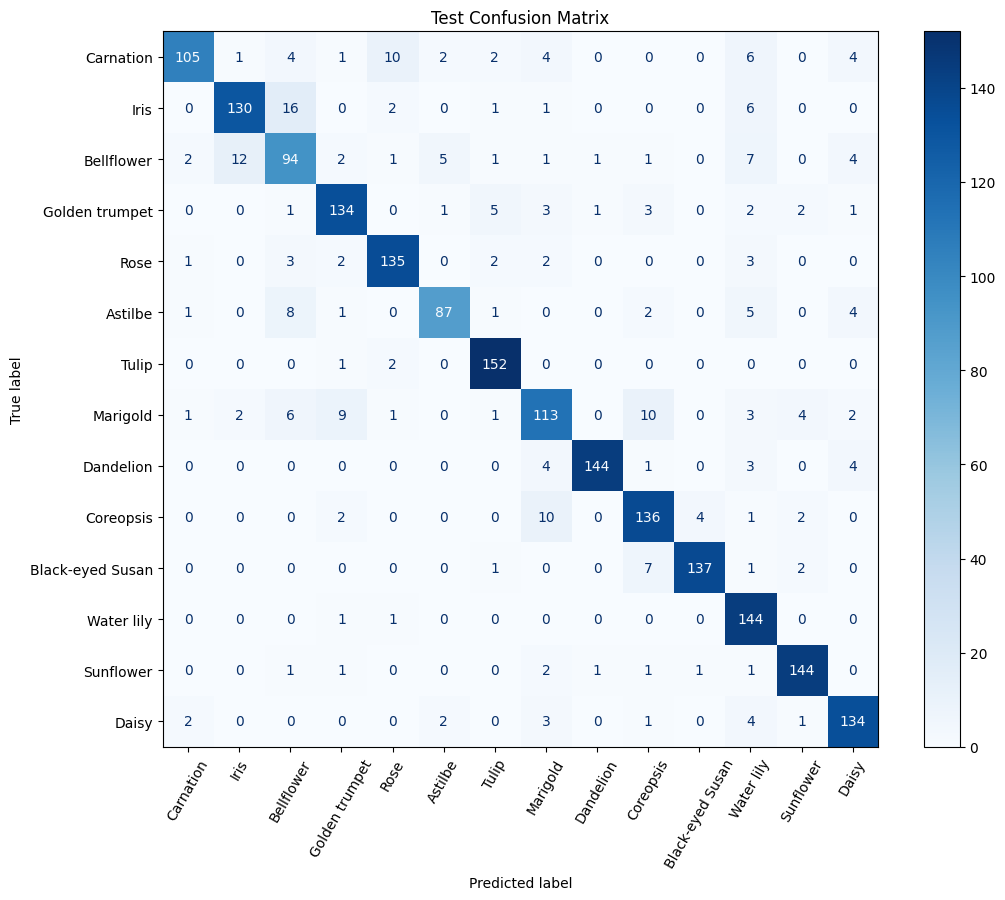

In [9]:
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="Train accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Learning Curve")
plt.legend()
plt.show()

probabilities = model.predict(test_ds, verbose=0)
y_pred = np.argmax(probabilities, axis=1)
y_true = test_df["category"].to_numpy()

print("Test accuracy:", round(accuracy_score(y_true, y_pred), 3))
print(classification_report(y_true, y_pred, labels=list(range(NUM_CLASSES)),
                            target_names=flower_names, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
fig, ax = plt.subplots(figsize=(11, 9))
ConfusionMatrixDisplay(cm, display_labels=flower_names).plot(ax=ax, xticks_rotation=60, cmap="Blues")
plt.title("Test Confusion Matrix")
plt.tight_layout()
plt.show()

## 9. Flower Prediction

Predict the flower category for an unseen test image

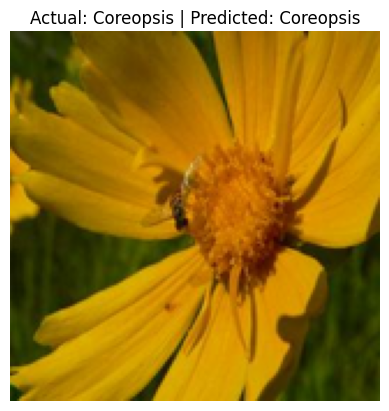

Model confidence: 74.0%


In [10]:
from PIL import Image

sample = test_df.iloc[0]
with Image.open(sample["full_path"]) as raw_image:
    image = raw_image.convert("RGB").resize(IMAGE_SIZE)
    image_array = np.asarray(image, dtype=np.float32)[None, ...]

scores = model.predict(image_array, verbose=0)[0]
predicted_class = int(np.argmax(scores))

plt.imshow(image)
plt.axis("off")
plt.title(f"Actual: {flower_names[int(sample['category'])]} | Predicted: {flower_names[predicted_class]}")
plt.show()
print("Model confidence:", f"{scores[predicted_class]:.1%}")

### Predicted vs. Actual Flowers

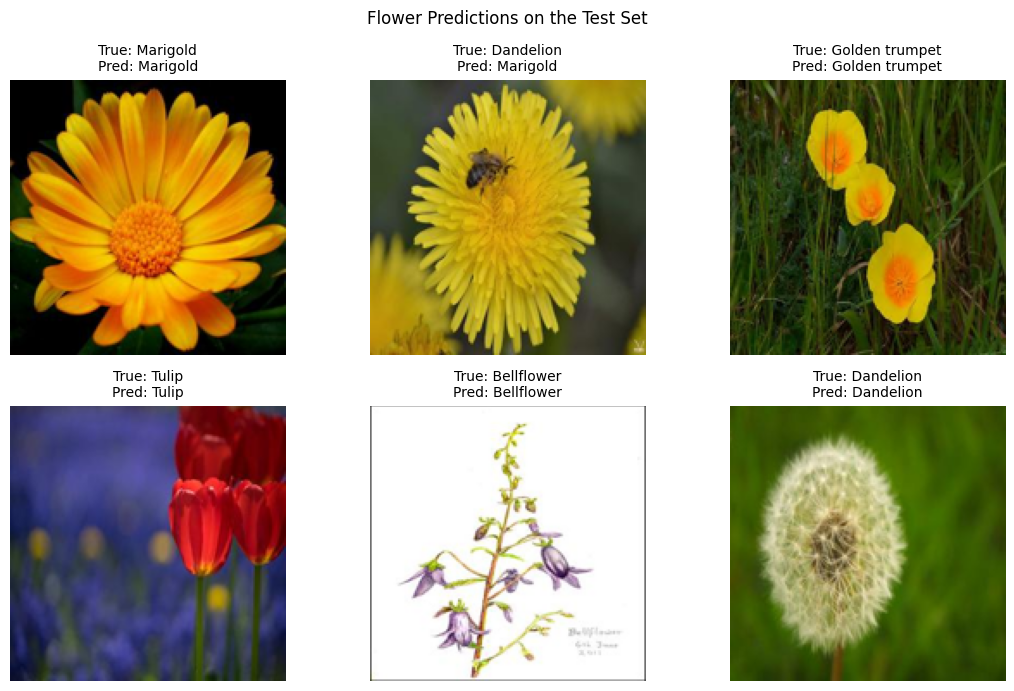

In [11]:
from PIL import Image

preview = test_df.sample(n=min(6, len(test_df)), random_state=RANDOM_STATE)
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for ax, (_, row) in zip(axes.flat, preview.iterrows()):
    with Image.open(row["full_path"]) as raw:
        img = raw.convert("RGB").resize(IMAGE_SIZE)
    scores = model.predict(np.asarray(img, dtype=np.float32)[None, ...], verbose=0)[0]
    pred = int(np.argmax(scores))
    true = int(row["category"])
    ax.imshow(img)
    ax.set_title(f"True: {flower_names[true]}\nPred: {flower_names[pred]}", fontsize=10)
    ax.axis("off")
plt.suptitle("Flower Predictions on the Test Set")
plt.tight_layout()
plt.show()

## 10. Save the Trained Model

Save the model for possible use in a future **Streamlit application**

In [12]:
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)
model.save(MODEL_DIR / "flower_classifier.keras")
print("Saved:", MODEL_DIR / "flower_classifier.keras")

Saved: models\flower_classifier.keras


## Conclusion

This project demonstrates an end-to-end **14-class flower image classification** workflow using CNN-based transfer learning

- Explored the dataset and visualized flower images and class distributions
- Trained a **MobileNetV2** classifier using 2,800 images for 5 epochs
- Evaluated the model on **2,047 held-out test images**
- Achieved **87.4% test accuracy** and approximately **0.87 macro F1-score**
- Visualized the confusion matrix and example predictions, then saved the trained model for future use

### Limitations

The original validation set contains only **98 images**, and training used a subset of the available images to reduce computation. Results may change with different data splits or more representative datasets. Performance on new real-world photos has not been established

### Future Improvement

Train using more images, evaluate on an additional external dataset, and optionally build a **Streamlit flower classifier**